# Step 4 — Exploratory analysis
All conclusions below are calculated from the project files. The partial day 2011-12-09 is excluded.

In [1]:
import sys
import pandas as pd
import numpy as np
import statsmodels
import matplotlib
print('sys.executable:', sys.executable)
print('sys.version:', sys.version)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('statsmodels:', statsmodels.__version__)
print('matplotlib:', matplotlib.__version__)

sys.executable: C:\Users\Admin\Desktop\retail-revenue-forecasting\.venv\Scripts\python.exe
sys.version: 3.12.8 (tags/v3.12.8:2dc476b, Dec  3 2024, 19:30:04) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.6
numpy: 2.5.4
statsmodels: 0.15.0
matplotlib: 3.11.2


In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from retail_forecast.data.eda import (eda_summary, weekday_profile, decompose_weekly, anomaly_details, cleaning_impact, cleaning_impact_steps)
from retail_forecast.data.load import load_config
config = load_config(ROOT / 'configs' / 'config.yaml')
clean = pd.read_csv(ROOT / 'data/interim/clean_transactions.csv', dtype={'InvoiceNo':'string','StockCode':'string','CustomerID':'string'}, parse_dates=['InvoiceDate'])
raw = pd.read_csv(ROOT / 'data/raw/online_retail.csv', dtype={'InvoiceNo':'string','StockCode':'string','CustomerID':'string'}, parse_dates=['InvoiceDate'])
daily = pd.read_csv(ROOT / 'data/processed/daily_revenue.csv', parse_dates=['date'])
weekly = pd.read_csv(ROOT / 'data/processed/weekly_revenue.csv', parse_dates=['date'])
anomalous = pd.read_csv(ROOT / 'data/processed/anomalous_days.csv', parse_dates=['date'])
transaction_counts = clean.assign(date=clean.InvoiceDate.dt.normalize()).groupby('date').size()
daily['n_transactions'] = daily.date.map(transaction_counts).fillna(0).astype(int)
summary = eda_summary(clean, daily)
profile = weekday_profile(daily)
impact = cleaning_impact(raw, clean)
cleaning_steps = cleaning_impact_steps(raw, pd.read_csv(ROOT / 'data/interim/cleaning_summary.csv'), config)
details = anomaly_details(clean, anomalous)
figures = ROOT / 'reports/figures'; figures.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

## a. Context and cleaning pipeline

In [3]:
cleaning_summary = pd.read_csv(ROOT / 'data/interim/cleaning_summary.csv')
display(cleaning_summary)
display(impact)
display(cleaning_steps)
print(f"Cleaning retains {len(clean):,} rows out of {len(raw):,}, or {len(clean)/len(raw):.1%}; cleaned revenue is £{clean.Revenue.sum():,.2f}.")

,step,rows_before,rows_after,removed,note
0,drop_exact_duplicates,541909,536641,5268,NaN
1,flag_cancellations,536641,536641,0,NaN
2,drop_cancelled_orders,536641,533763,2878,NaN
3,exclude_cancellations,533763,524512,9251,NaN
4,remove_invalid_prices,524512,522000,2512,NaN
5,remove_non_product_codes,522000,519726,2274,NaN
6,remove_non_product_invoices,519726,519726,0,NaN
7,remove_invalid_quantities,519726,519726,0,NaN
8,winsorize,519726,519726,0,0 plafonnements
9,add_revenue,519726,519726,0,0 ligne supprimée


,dataset,rows,revenue
0,raw,541909,9.747748e+06
1,raw_without_cancellations,532621,1.064456e+07
2,clean,519726,9.821479e+06


,step,rows_removed,revenue_removed
0,drop_exact_duplicates,5268,21740.980
1,flag_cancellations,0,0.000
2,drop_cancelled_orders,2878,444831.780
3,exclude_cancellations,9251,-893979.730
4,remove_invalid_prices,2512,-22124.120
5,remove_non_product_codes,2274,375799.811
6,remove_non_product_invoices,0,0.000
7,remove_invalid_quantities,0,0.000
8,winsorize,0,0.000
9,add_revenue,0,0.000


Cleaning retains 519,726 rows out of 541,909, or 95.9%; cleaned revenue is £9,821,479.21.


### Conclusion — cleaning

Cleaning retains **519,726 rows out of 541,909**, or **95.9%**, for calculated cleaned revenue of **£9,821,479.21**. Cancellations and non-product codes are therefore handled before modeling.

## b. Daily and weekly revenue

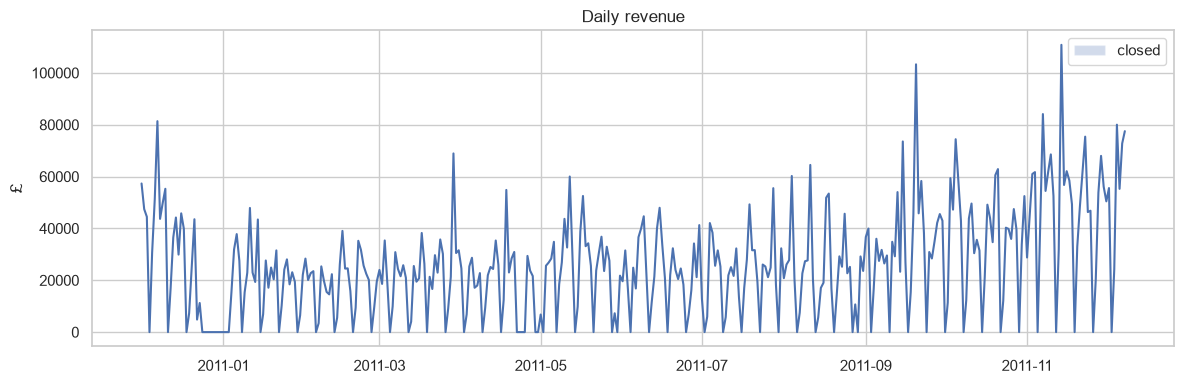

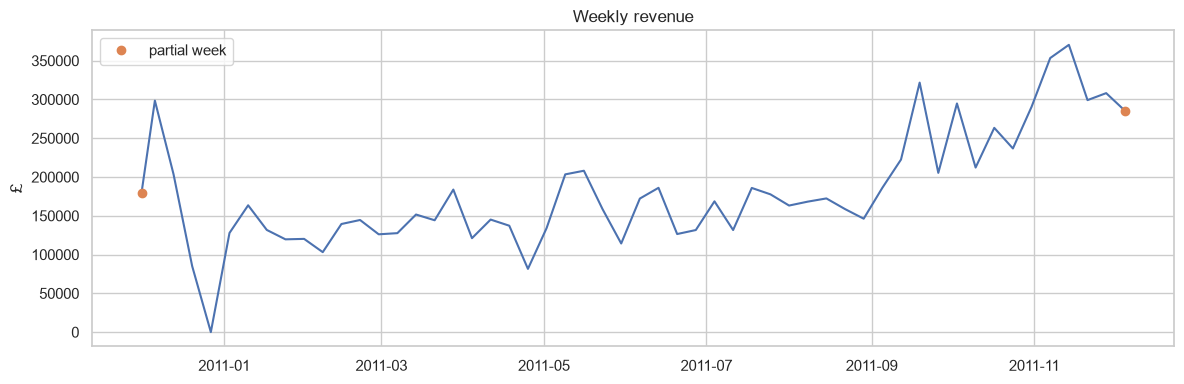

Series: 2010-12-01 to 2011-12-08, 373 days.
IDXMAX: date=2011-11-14, revenue=£110,815.68
TOP5_DAYS:
      date   revenue
2011-11-14 110815.68
2011-09-20 103293.08
2011-11-07  84108.61
2010-12-07  81368.44
2011-12-05  80011.23
MONTHLY_ACTIVE_MEANS_COMPLETE=
                 mean  n_days
month                        
2011-01  23530.538750      24
2011-02  21030.000417      24
2011-03  25270.172593      27
2011-04  24264.032905      21
2011-05  29305.501600      25
2011-06  26539.324231      26
2011-07  26250.858115      26
2011-08  27506.607308      26
2011-09  39140.043885      26
2011-10  41190.790385      26
2011-11  55340.449231      26
JAN_OCT_TREND: January=£23,530.54, October=£41,190.79, change=£17,660.25 (75.05%); linear January-October slope=£73.63/day. With one annual cycle, the underlying trend cannot be identified reliably.


In [4]:
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(daily.date, daily.revenue)
ax.fill_between(daily.date, 0, daily.revenue, where=~daily.is_trading_day, alpha=.25, label='closed')
ax.set(title='Daily revenue', ylabel='£'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'daily_revenue.png'); plt.show()
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(weekly.date, weekly.revenue)
partial = weekly.loc[weekly.is_partial_week]; ax.plot(partial.date, partial.revenue, linestyle='None', marker='o', label='partial week')
ax.set(title='Weekly revenue', ylabel='£'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'weekly_revenue.png'); plt.show()
max_day = daily.loc[daily.revenue.idxmax()]
top5_days = daily.nlargest(5, 'revenue')[['date', 'revenue']]
active_eda = daily.loc[daily.is_trading_day & ~daily.date.between('2010-12-24', '2011-01-03')].copy()
active_eda['month'] = active_eda.date.dt.to_period('M').astype(str)
complete_months = active_eda.loc[active_eda.month.between('2011-01', '2011-11')].copy()
monthly_stats = complete_months.groupby('month').agg(total=('revenue', 'sum'), mean=('revenue', 'mean'), n_days=('date', 'size'))
nov_stats = monthly_stats.loc['2011-11']
nov_total_rank = int(monthly_stats.total.rank(ascending=False, method='min').loc['2011-11'])
nov_mean_rank = int(monthly_stats['mean'].rank(ascending=False, method='min').loc['2011-11'])
nov_total_ratio = nov_stats.total / monthly_stats.total.median()
nov_mean_ratio = nov_stats['mean'] / monthly_stats['mean'].median()
jan_mean = monthly_stats.loc['2011-01', 'mean']; oct_mean = monthly_stats.loc['2011-10', 'mean']
jan_oct = complete_months.loc[complete_months.month.between('2011-01', '2011-10')]
trend_slope = float(__import__('numpy').polyfit(range(len(jan_oct)), jan_oct.revenue.to_numpy(float), 1)[0])
print(f"Series: {daily.date.min().date()} to {daily.date.max().date()}, {len(daily)} days.")
print(f"IDXMAX: date={max_day.date.date()}, revenue=£{max_day.revenue:,.2f}")
print('TOP5_DAYS:'); print(top5_days.to_string(index=False))
print('MONTHLY_ACTIVE_MEANS_COMPLETE='); print(monthly_stats[['mean', 'n_days']].to_string())
print(f"JAN_OCT_TREND: January=£{jan_mean:,.2f}, October=£{oct_mean:,.2f}, change=£{oct_mean-jan_mean:,.2f} ({oct_mean/jan_mean-1:.2%}); linear January-October slope=£{trend_slope:,.2f}/day. With one annual cycle, the underlying trend cannot be identified reliably.")

### Conclusion — trend

The maximum calculated by `daily.revenue.idxmax()` is **£110,815.68 on 2011-11-14**. Across complete months from January to November 2011, the active-day average rises from **£23,530.54 in January** to **£41,190.79 in October**, or **+75.05%** excluding November; the January-October slope is **£73.63/day**. With one annual cycle, the underlying trend cannot be identified reliably.

### Conclusion — observed closure

The window from **December 24, 2010 to January 3, 2011** contains **0 transactions** and **£0.00** in revenue. For Christmas 2011, this closure is a displayed calendar assumption because only one Christmas is observed.

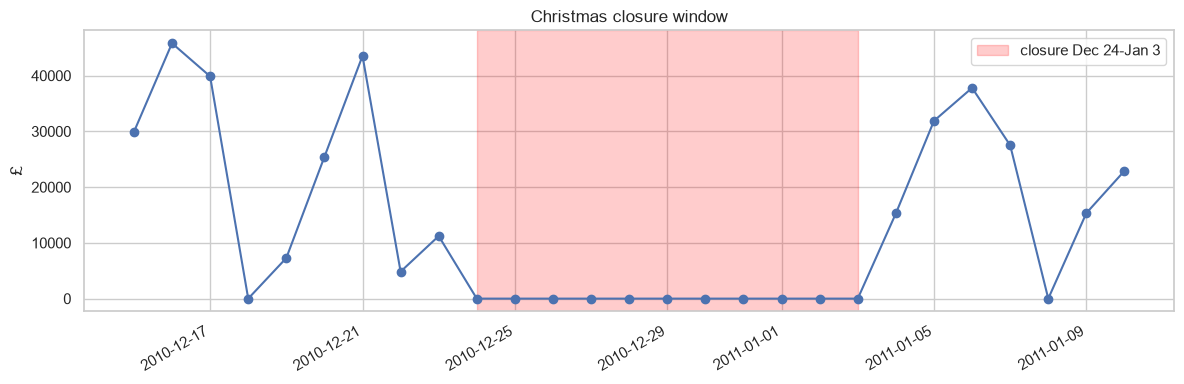

Window 2010-12-15 -> 2011-01-10: 27 days, 20122 transactions during closure, £0.00 during closure.


In [5]:
closure_window = daily.loc[daily.date.between('2010-12-15', '2011-01-10')]
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(closure_window.date, closure_window.revenue, marker='o')
ax.axvspan(pd.Timestamp('2010-12-24'), pd.Timestamp('2011-01-03'), alpha=.2, color='red', label='closure Dec 24-Jan 3')
ax.set(title='Christmas closure window', ylabel='£'); ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(figures/'christmas_closure_window.png'); plt.show()
print(f"Window 2010-12-15 -> 2011-01-10: {len(closure_window)} days, {int(closure_window.n_transactions.sum())} transactions during closure, £{closure_window.loc[closure_window.date.between('2010-12-24','2011-01-03'),'revenue'].sum():,.2f} during closure.")

## c. Weekday profile

,weekday,mean,median,n_days
0,Friday,30660.704306,26327.730,49
1,Monday,35399.452979,28397.560,47
2,Sunday,15815.592220,12161.890,50
3,Thursday,39622.375472,35596.740,53
4,Tuesday,37889.883288,32955.605,52
5,Wednesday,33295.583585,27774.660,53


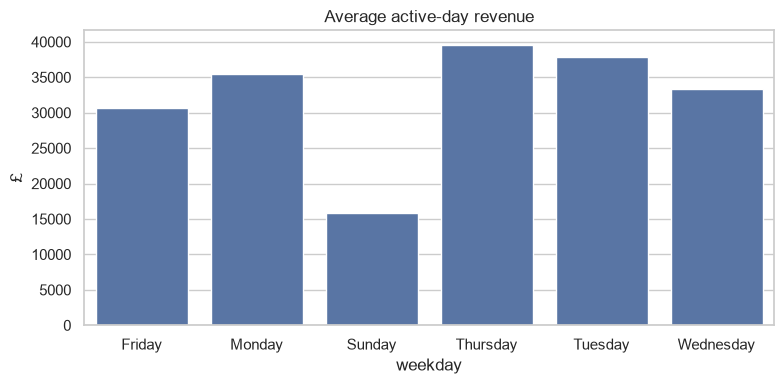

Saturday accounts for 53 days in the series and 0.00 £ in revenue.


In [6]:
display(profile)
fig, ax = plt.subplots(figsize=(8, 4)); sns.barplot(profile, x='weekday', y='mean', ax=ax)
ax.set(title='Average active-day revenue', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'weekday_profile.png'); plt.show()
print(f"Saturday accounts for {int((daily.date.dt.dayofweek==5).sum())} days in the series and {int(daily.loc[daily.date.dt.dayofweek==5, "revenue"].sum()):,.2f} £ in revenue.")

### Conclusion — weekly seasonality

The calculated profile covers **6 active days**: Monday to Friday and Sunday. Saturday is structurally closed in the series and should be modeled with the `is_trading_day` feature, not as a random absence.

## d. Monthly seasonality

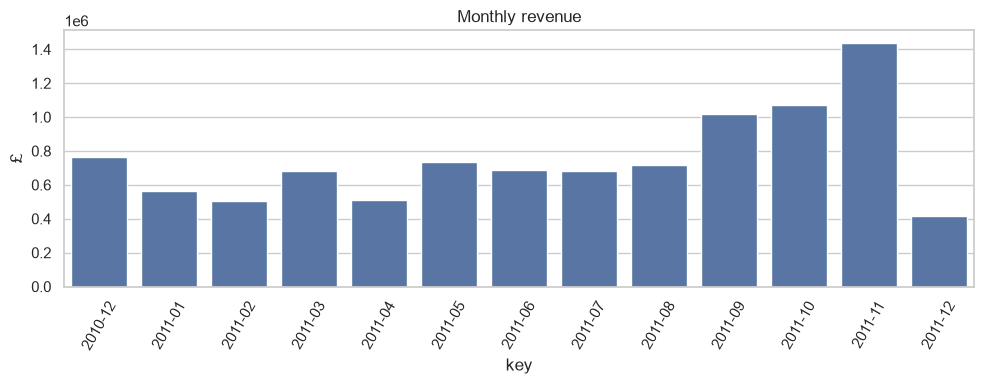

NOVEMBER_TOTAL: £1,438,851.68; rank=1/11, median_month_ratio=2.09x.
NOVEMBER_ACTIVE_DAILY_MEAN: £55,340.45; rank=1/11, median_monthly_mean_ratio=2.09x; active days=26.
DECEMBER_2010: December 2010 is affected by the closure from the 24th to the 31st, with 20 observed active days; excluded from ranking.
DECEMBER_PARTIAL: December 2011 is partial through 2011-12-08, with 7 observed active days; excluded from ranking.
CLOSURE: 0 transactions and £0.00 from December 24 to January 3.


In [7]:
monthly = summary.query("dimension == 'month'")
fig, ax = plt.subplots(figsize=(10, 4)); sns.barplot(monthly, x='key', y='revenue', ax=ax); ax.tick_params(axis='x', rotation=60)
ax.set(title='Monthly revenue', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'monthly_revenue.png'); plt.show()
nov = monthly.loc[monthly.key.eq('2011-11'), 'revenue'].iloc[0]
print(f"NOVEMBER_TOTAL: £{nov:,.2f}; rank={nov_total_rank}/{len(monthly_stats)}, median_month_ratio={nov_total_ratio:.2f}x.")
print(f"NOVEMBER_ACTIVE_DAILY_MEAN: £{nov_stats['mean']:,.2f}; rank={nov_mean_rank}/{len(monthly_stats)}, median_monthly_mean_ratio={nov_mean_ratio:.2f}x; active days={int(nov_stats['n_days'])}.")
observed_monthly = active_eda.groupby('month').agg(n_days=('date', 'size'))
print(f"DECEMBER_2010: December 2010 is affected by the closure from the 24th to the 31st, with {int(observed_monthly.loc['2010-12', 'n_days'])} observed active days; excluded from ranking.")
print(f"DECEMBER_PARTIAL: December 2011 is partial through {daily.date.max().date()}, with {int(observed_monthly.loc['2011-12','n_days'])} observed active days; excluded from ranking.")
print(f"CLOSURE: {int(daily.loc[daily.date.between('2010-12-24','2011-01-03'),'n_transactions'].sum())} transactions and £{daily.loc[daily.date.between('2010-12-24','2011-01-03'),'revenue'].sum():,.2f} from December 24 to January 3.")

### Conclusion — monthly seasonality

Across the **11 complete months from January to November 2011**, November ranks first in total revenue (**£1,438,851.68**, **2.09x** the median) and first in active-day average (**£55,340.45**, **2.09x**). December 2010 is affected by the closure from the 24th to the 31st, and December 2011 is partial through the 8th; both months are excluded from ranking.

## e. Weekly decomposition

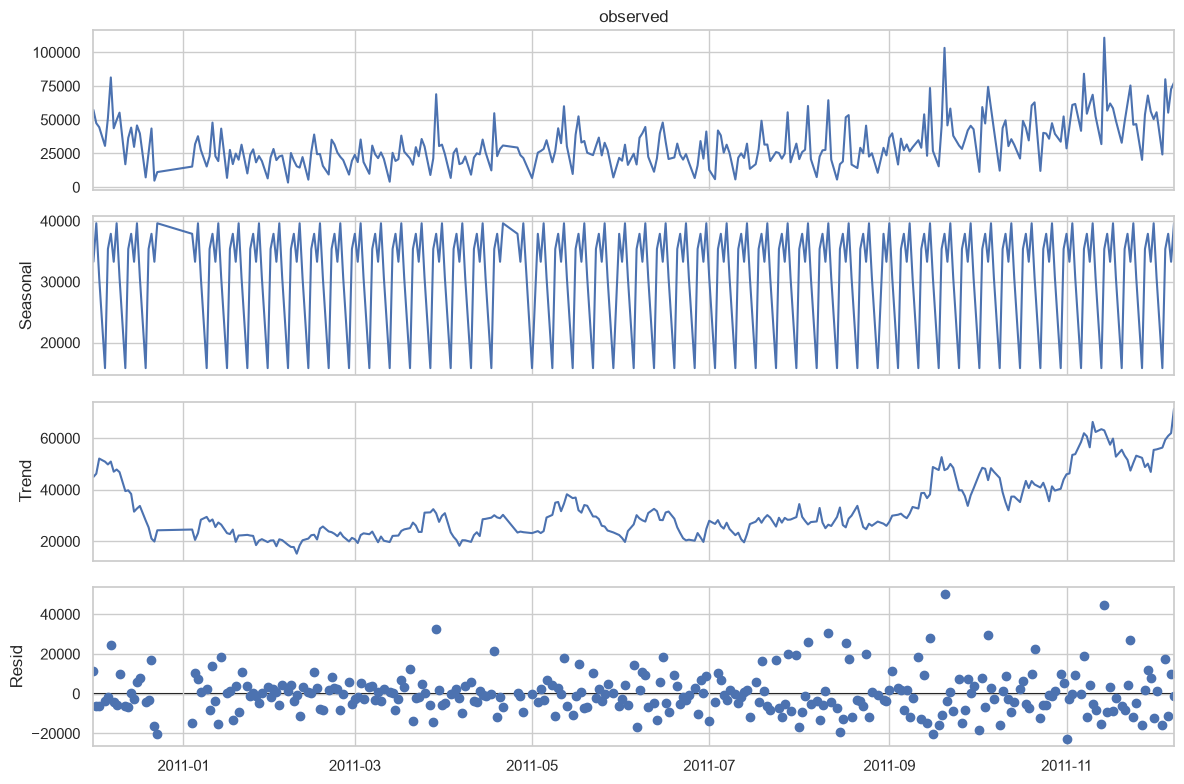

DECOMPOSITION_DAYS: 304 days after excluding closed days and the December 24-January 3 window.
Method: closed days and the December 24-January 3 window removed; seasonality = average by weekday and residual = deviation after a rolling trend of 7 active observations.


In [8]:
decomp = decompose_weekly(daily)
fig = decomp.plot(); fig.set_size_inches(12, 8); fig.tight_layout(); fig.savefig(figures/'decomposition.png'); plt.show()
print(f"DECOMPOSITION_DAYS: {len(decomp.observed)} days after excluding closed days and the December 24-January 3 window.")
print('Method: closed days and the December 24-January 3 window removed; seasonality = average by weekday and residual = deviation after a rolling trend of 7 active observations.')

### Conclusion — decomposition

The decomposition uses a **7-day** weekly period and covers exactly **304 active days** after excluding closed days and the December 24 to January 3 window. Only the weekly component is robustly interpretable; annual seasonality is limited by the single observed Christmas.

## f. Anomalous days

,date,rank,InvoiceNo,StockCode,CustomerID,Quantity,UnitPrice,Revenue,share_of_day
0,2011-03-29,1,548203,22197,<NA>,637,1.95,1242.15,0.018023
1,2011-03-29,2,548011,22629,14646.0,640,1.65,1056.00,0.015322
2,2011-03-29,3,548011,22630,14646.0,640,1.65,1056.00,0.015322
3,2011-08-04,1,562439,84879,12931.0,2880,1.45,4176.00,0.069340
4,2011-08-04,2,562439,22191,12931.0,348,7.65,2662.20,0.044205
5,2011-08-04,3,562439,22197,12931.0,1900,0.72,1368.00,0.022715
6,2011-08-11,1,563074,84879,12931.0,968,1.45,1403.60,0.021766
7,2011-08-11,2,563074,22992,12931.0,432,1.65,712.80,0.011054
8,2011-08-11,3,563074,22991,12931.0,432,1.65,712.80,0.011054
9,2011-08-17,1,563590,23243,17450.0,352,5.15,1812.80,0.034973


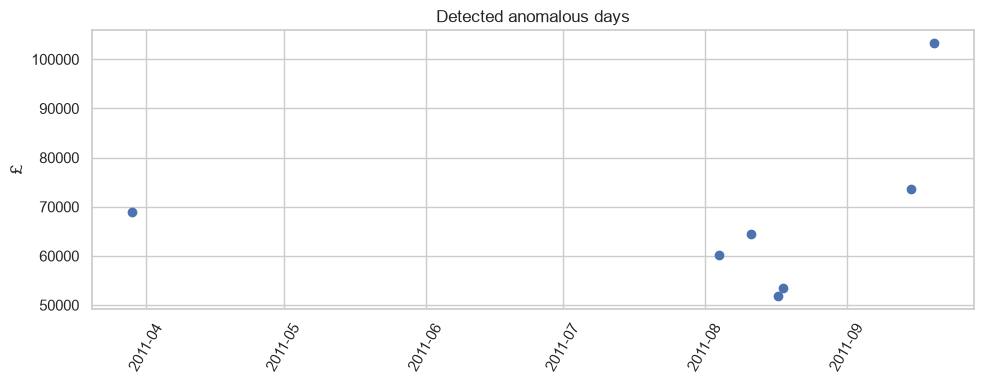

2011-03-29: top 3 = £3,354.15, share = 4.9%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-08-04: top 3 = £8,206.20, share = 13.6%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-08-11: top 3 = £2,829.20, share = 4.4%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-08-17: top 3 = £4,220.00, share = 8.1%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-08-18: top 3 = £3,150.76, share = 5.9%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-09-15: top 3 = £7,328.00, share = 10.0%; conclusion: inspect the three largest lines before classifying the day as a true peak.
2011-09-20: top 3 = £13,935.88, share = 13.5%; conclusion: inspect the three largest lines before classifying the day as a true peak.


,CustomerID,revenue,customer_key,share_of_day
0,17450.0,66818.18,17450,0.646880
1,14866.0,5460.96,14866,0.052869
2,<NA>,5084.01,<NA>,0.049219
3,13767.0,2250.90,13767,0.021791
4,15341.0,2020.52,15341,0.019561


CustomerID 17450 represents 64.69% of 2011-09-20 revenue.


In [9]:
display(details)
fig, ax = plt.subplots(figsize=(10, 4)); ax.scatter(anomalous.date, anomalous.revenue); ax.tick_params(axis='x', rotation=60)
ax.set(title='Detected anomalous days', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'anomalies.png'); plt.show()
for date, group in details.groupby('date'):
    print(f"{date.date()}: top 3 = £{group.Revenue.sum():,.2f}, share = {group.share_of_day.sum():.1%}; conclusion: inspect the three largest lines before classifying the day as a true peak.")
day_0920 = clean.loc[clean.InvoiceDate.dt.normalize().eq(pd.Timestamp('2011-09-20'))].copy()
customer_0920 = day_0920.groupby('CustomerID', dropna=False)['Revenue'].sum().sort_values(ascending=False).head(5).rename('revenue').reset_index()
customer_0920['customer_key'] = customer_0920.CustomerID.astype('string').str.replace(r'\.0$', '', regex=True)
customer_0920['share_of_day'] = customer_0920.revenue / day_0920.Revenue.sum()
display(customer_0920)
share_17450 = customer_0920.loc[customer_0920.customer_key.eq('17450'), 'share_of_day'].iloc[0]
print(f"CustomerID 17450 represents {share_17450:.2%} of 2011-09-20 revenue.")

### Conclusion — anomalies

The **7 anomalous days** represent **£475,740.25**, or **4.86%** of total daily revenue. 2011-09-20 is included and should be flagged as an unpredictable event: customer **17450 represents 64.69%** of that day's revenue.

,scope,mean,median,std,share_total
0,avec_7_anomalies,26251.619767,24850.56,19998.524220,1.000000
1,sans_7_anomalies,25453.863178,24525.65,19199.241292,0.951415


ANOMALY_DATES: 2011-03-29, 2011-08-04, 2011-08-11, 2011-08-17, 2011-08-18, 2011-09-15, 2011-09-20


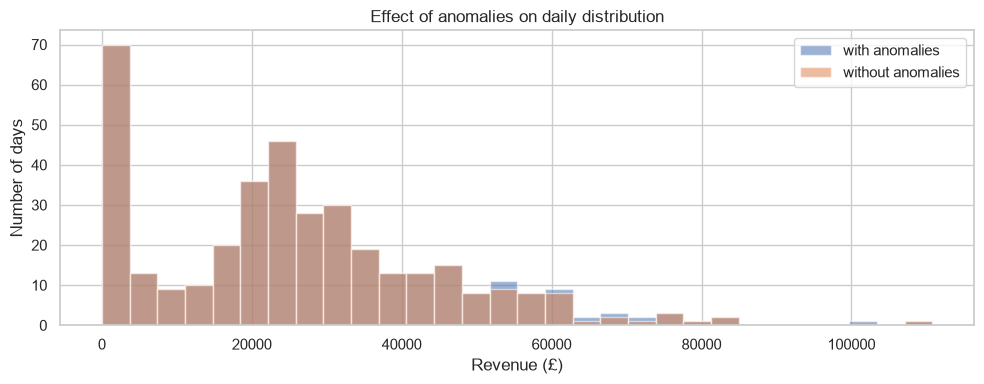

With anomalies: mean £26,251.62, median £24,850.56, standard deviation £19,998.52, share 100.00%.
Without anomalies: mean £25,453.86, median £24,525.65, standard deviation £19,199.24, share 95.14%.
ANOMALY_RELATIVE_DROP: mean=3.04%, standard deviation=4.00%; conclusion: anomalies explain little variance if the standard deviation decrease remains small.


In [10]:
anomaly_dates = set(anomalous.date)
with_anomalies = daily.revenue
without_anomalies = daily.loc[~daily.date.isin(anomaly_dates), 'revenue']
anomaly_effect = pd.DataFrame([
    {'scope': 'avec_7_anomalies', 'mean': with_anomalies.mean(), 'median': with_anomalies.median(), 'std': with_anomalies.std(), 'share_total': with_anomalies.sum() / daily.revenue.sum()},
    {'scope': 'sans_7_anomalies', 'mean': without_anomalies.mean(), 'median': without_anomalies.median(), 'std': without_anomalies.std(), 'share_total': without_anomalies.sum() / daily.revenue.sum()},
])
display(anomaly_effect)
print('ANOMALY_DATES:', ', '.join(anomalous.date.dt.strftime('%Y-%m-%d')))
fig, ax = plt.subplots(figsize=(10, 4)); ax.hist(with_anomalies, bins=30, alpha=.55, label='with anomalies'); ax.hist(without_anomalies, bins=30, alpha=.55, label='without anomalies'); ax.set(title='Effect of anomalies on daily distribution', xlabel='Revenue (£)', ylabel='Number of days'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'anomaly_effect.png'); plt.show()
print(f"With anomalies: mean £{with_anomalies.mean():,.2f}, median £{with_anomalies.median():,.2f}, standard deviation £{with_anomalies.std():,.2f}, share {with_anomalies.sum()/daily.revenue.sum():.2%}.")
print(f"Without anomalies: mean £{without_anomalies.mean():,.2f}, median £{without_anomalies.median():,.2f}, standard deviation £{without_anomalies.std():,.2f}, share {without_anomalies.sum()/daily.revenue.sum():.2%}.")
mean_drop = 1 - without_anomalies.mean()/with_anomalies.mean()
std_drop = 1 - without_anomalies.std()/with_anomalies.std()
print(f"ANOMALY_RELATIVE_DROP: mean={mean_drop:.2%}, standard deviation={std_drop:.2%}; conclusion: anomalies explain little variance if the standard deviation decrease remains small.")

## g. Pays et produits

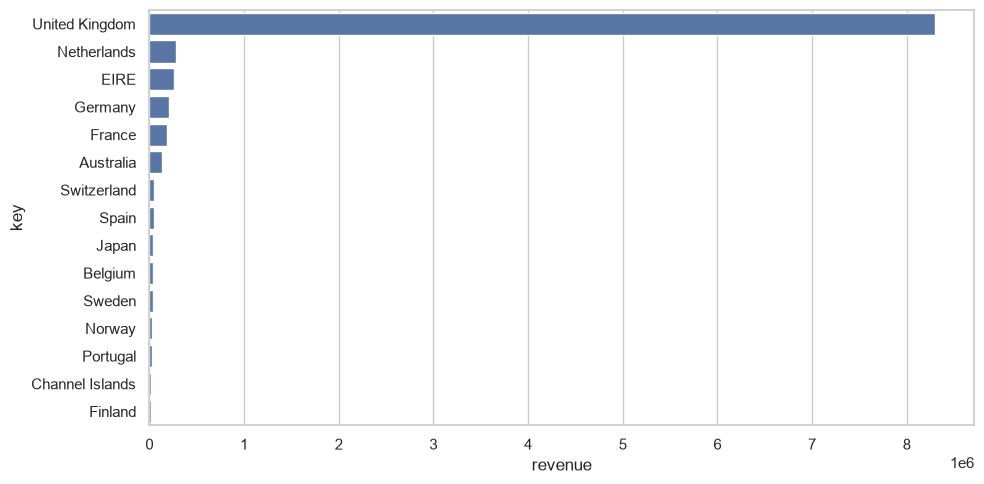

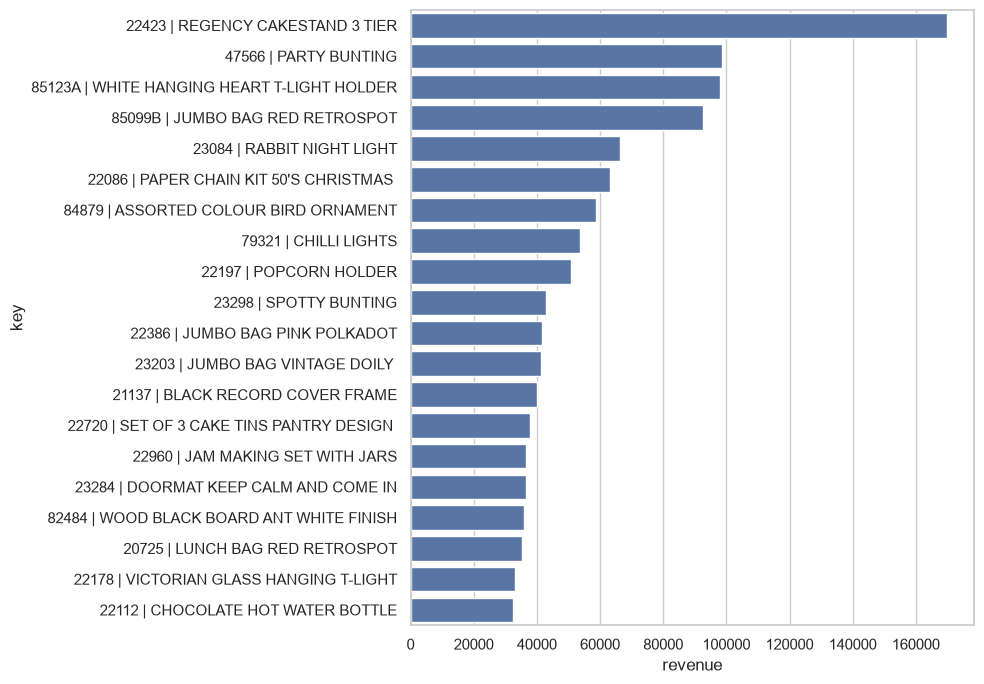

The United Kingdom represents 84.5% of cleaned revenue among summarized countries.


In [11]:
country = summary.query("dimension == 'country'").sort_values('revenue', ascending=False).head(15)
products = summary.query("dimension == 'product'").head(20)
fig, ax = plt.subplots(figsize=(10, 5)); sns.barplot(country, y='key', x='revenue', ax=ax); fig.tight_layout(); fig.savefig(figures/'country.png'); plt.show()
fig, ax = plt.subplots(figsize=(10, 7)); sns.barplot(products, y='key', x='revenue', ax=ax); fig.tight_layout(); fig.savefig(figures/'products.png'); plt.show()
uk = country.loc[country.key.eq('United Kingdom'), 'revenue'].iloc[0]
print(f"The United Kingdom represents {uk/clean.Revenue.sum():.1%} of cleaned revenue among summarized countries.")

### Conclusion — geographic concentration

The United Kingdom represents **84.46%** of calculated cleaned revenue. Geographic concentration is therefore strong; other countries should be monitored as minority segments rather than mixed without control.

## h. Summary and implications

In [12]:
print(f"1. {len(clean):,} cleaned transactions produce £{clean.Revenue.sum():,.2f}.")
print(f"2. The series contains {len(daily)} days and {int((~daily.is_trading_day).sum())} inactive days.")
print(f"3. The daily peak reaches £{daily.revenue.max():,.2f} on {daily.loc[daily.revenue.idxmax(), "date"].date()}.")
print(f"4. November totals £{nov:,.2f}; only one Christmas is observed, so year-end seasonality is fragile.")
print(f"5. The {len(anomalous)} anomalous days should be retained as candidate events, not automatically removed.")
print(f"6. The series contains {int((daily.n_transactions==0).sum())} days without transactions; closed days must be handled explicitly in features.")
print('Implications: the model must incorporate closures, the November peak, and uncertainty from a single Christmas cycle; the target remains total revenue.')

1. 519,726 cleaned transactions produce £9,821,479.21.
2. The series contains 373 days and 69 inactive days.
3. The daily peak reaches £110,815.68 on 2011-11-14.
4. November totals £1,438,851.68; only one Christmas is observed, so year-end seasonality is fragile.
5. The 7 anomalous days should be retained as candidate events, not automatically removed.
6. The series contains 69 days without transactions; closed days must be handled explicitly in features.
Implications: the model must incorporate closures, the November peak, and uncertainty from a single Christmas cycle; the target remains total revenue.


### Conclusion — summary

The calculated results combine **304 decomposed days**, **69 inactive days**, a daily maximum of **£110,815.68 on 2011-11-14**, a **75.05%** increase between January and October in active-day averages, **7 anomalies**, and **84.46%** UK concentration. With one annual cycle, the underlying trend remains uncertain; features should represent closures and events without removing observations.